# 11. CUDA를 이용한 Monte Carlo 병렬연산

강의록의 CUDA 장에 대응합니다. 시간 방향은 순서대로 진행하고, 서로 독립인 경로를 배열로 함께 계산합니다.

**사용 순서:** 위에서 아래로 실행합니다. 저장된 출력 중 CPU 가격과 표준오차는 실제 계산 결과입니다. 현재 제작 환경에는 CUDA GPU가 없어 **GPU 수치·실행시간·속도 향상률은 미측정**입니다. GPU 셀의 저장된 출력은 이 사실을 알리는 실행 결과이며, GPU 계산 결과를 대신하지 않습니다. NVIDIA GPU와 CuPy가 준비된 컴퓨터에서 다시 실행하면 같은 셀이 GPU 계산을 수행합니다.

모형은 위험중립측도 $\mathbb{Q}$ 아래에서
$$dX_t=\kappa(\theta-X_t)\,dt+\sigma\,dW_t^{\mathbb{Q}},\qquad
P(0,T)=\mathbb{E}^{\mathbb{Q}}\!\left[e^{-\int_0^T X_t\,dt}\right]$$
입니다. CPU와 GPU 모두 강의록의 오른쪽 끝점 적분합과 배정밀도를 사용합니다.

## 실행 환경 확인

이 보조 셀은 CuPy 설치와 실제 GPU 연산 가능 여부를 확인합니다. GPU가 없더라도 CPU 실습은 계속 진행됩니다.

In [1]:
import importlib.util
import platform
import sys
import numpy as np
import matplotlib.pyplot as plt

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
GPU_AVAILABLE = False
GPU_REASON = "CuPy가 설치되어 있지 않습니다."
if importlib.util.find_spec("cupy") is not None:
    try:
        import cupy as cp
    except (ImportError, OSError) as exc:
        GPU_REASON = f"CuPy를 불러오지 못했습니다: {exc}"
    else:
        try:
            if cp.cuda.runtime.getDeviceCount() > 0:
                cp.zeros(1, dtype=float).sum().item()
                cp.cuda.get_current_stream().synchronize()
                GPU_AVAILABLE = True
                GPU_REASON = "CUDA 배열 연산 확인 완료"
            else:
                GPU_REASON = "CUDA 장치가 없습니다."
        except cp.cuda.runtime.CUDARuntimeError as exc:
            GPU_REASON = f"CUDA 초기화 실패: {exc}"
print("GPU 실습:", GPU_REASON)

Python: 3.13.1
NumPy: 2.2.3


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\cupy\_environment.py:286: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


GPU 실습: CUDA 배열 연산 확인 완료


## Monte Carlo 계산은 어디에서 병렬화되는가

강의록의 한 줄을 독립적으로 실행할 수 있도록 네 경로의 초기값과 난수를 먼저 준비합니다.

In [2]:
kappa, theta, sigma, dt = 0.7, 0.04, 0.015, 0.01
scale = sigma * np.sqrt(dt)
x = np.full(4, 0.03, dtype=float)
z = np.random.default_rng(20260809).standard_normal(4)
print("갱신 전:", x)
x += kappa * (theta - x) * dt + scale * z
print("갱신 후:", x)

갱신 전: [0.03 0.03 0.03 0.03]
갱신 후: [0.02927561 0.03117675 0.03060631 0.02825153]


## Windows에서 CUDA 실행환경 준비하기

**강의록 Listing 2**

Windows PowerShell에서 직접 실행하는 준비 명령입니다. 노트북의 Python 셀에서는 실행하지 않습니다.

```powershell
nvidia-smi
```

**강의록 Listing 3**

Windows PowerShell에서 직접 실행하는 준비 명령입니다. 노트북의 Python 셀에서는 실행하지 않습니다.

```powershell
py -m venv .venv
.\.venv\Scripts\python.exe -m pip install --upgrade pip setuptools
.\.venv\Scripts\python.exe -m pip install numpy
.\.venv\Scripts\python.exe -m pip install "cupy-cuda12x[ctk]"
.\.venv\Scripts\python.exe -m pip install ipykernel
```

### CuPy 설치와 GPU 배열 연산 확인

GPU가 있을 때 원문 코드를 실행합니다. GPU가 없으면 미실행 이유를 표시합니다.

In [3]:
if GPU_AVAILABLE:
    import sys
    import cupy as cp

    print("Python:", sys.executable)
    print("CuPy:", cp.__version__)
    print("GPU count:", cp.cuda.runtime.getDeviceCount())

    x = cp.array([1.0, 2.0, 3.0], dtype=float)
    y = cp.sum(x * x, dtype=float)
    cp.cuda.get_current_stream().synchronize()

    print("dtype:", x.dtype)
    print("itemsize:", x.itemsize)
    print("result:", float(y.item()))
else:
    print("GPU 계산 미실행:", GPU_REASON)

Python: c:\Users\User\AppData\Local\Programs\Python\Python313\python.exe
CuPy: 14.2.0
GPU count: 1
dtype: float64
itemsize: 8
result: 14.0


**강의록 Listing 5**

강의록에 제시된 **GPU 정상 출력의 예시**입니다. 이 제작 환경에서 측정한 값은 아닙니다.

```text
dtype: float64
itemsize: 8
result: 14.0
```

## 금융 계산에서 실수형을 유지하는 방법

GPU가 있을 때 원문 코드를 실행합니다. GPU가 없으면 미실행 이유를 표시합니다.

In [4]:
if GPU_AVAILABLE:
    x = cp.full(100_000, 0.03, dtype=float)
    integral = cp.zeros(100_000, dtype=float)
    rng = cp.random.default_rng(20260809)
    z = rng.standard_normal(100_000, dtype=float)

    assert x.itemsize == 8
    assert integral.itemsize == 8
    assert z.itemsize == 8
    print("GPU 배열 자료형:", x.dtype, integral.dtype, z.dtype)
else:
    print("GPU 계산 미실행:", GPU_REASON)

GPU 배열 자료형: float64 float64 float64


## NumPy 배열과 CuPy 배열

### CPU 배열을 GPU로 옮기고 다시 가져오기

GPU가 있을 때 원문 코드를 실행합니다. GPU가 없으면 미실행 이유를 표시합니다.

In [5]:
if GPU_AVAILABLE:
    import numpy as np
    import cupy as cp

    rates_cpu = np.array([0.02, 0.03, 0.04], dtype=float)
    rates_gpu = cp.asarray(rates_cpu, dtype=float)
    discount_gpu = cp.exp(-rates_gpu * 5.0)
    discount_cpu = cp.asnumpy(discount_gpu)

    print(discount_cpu)
else:
    print("GPU 계산 미실행:", GPU_REASON)

[0.90483742 0.86070798 0.81873075]


## OU 단기금리와 무이표채권 가격

앞의 설명용 상태와 섞이지 않도록 NumPy 배열을 다시 준비합니다. **금리를 먼저 갱신한 후 적분값을 더하는 순서**를 확인합니다.

In [6]:
kappa, theta, sigma, dt = 0.7, 0.04, 0.015, 0.01
scale = sigma * np.sqrt(dt)
x = np.full(4, 0.03, dtype=float)
integral = np.zeros(4, dtype=float)
z = np.random.default_rng(20260809).standard_normal(4)
x += kappa * (theta - x) * dt + scale * z
integral += x * dt
print("금리:", x)
print("누적 적분:", integral)

금리: [0.02927561 0.03117675 0.03060631 0.02825153]
누적 적분: [0.00029276 0.00031177 0.00030606 0.00028252]


## NumPy로 CPU 기준 프로그램 작성하기

### 모형 파라미터와 계산규모 설정

In [20]:
import math
import numpy as np

params = (0.03, 0.7, 0.04, 0.015, 5.0)
n_paths = 1_000_000
n_steps = 10_000
seed = 20260809

### NumPy를 이용한 CPU Monte Carlo

In [21]:
def bond_mc_cpu(
    params,
    n_paths,
    n_steps,
    seed,
):
    x0, kappa, theta, sigma, maturity = map(float, params)

    counts = (("n_paths", n_paths, 2), ("n_steps", n_steps, 1), ("seed", seed, 0))
    for name, value, minimum in counts:
        if isinstance(value, (bool, np.bool_)):
            raise TypeError(f"{name} must not be bool")
        if not isinstance(value, (int, np.integer)):
            raise TypeError(f"{name} must be an integer")
        if value < minimum:
            raise ValueError(f"{name} must be at least {minimum}")
    n_paths = int(n_paths)
    n_steps = int(n_steps)
    seed = int(seed)
    if not np.isfinite([x0, kappa, theta, sigma, maturity]).all():
        raise ValueError("model parameters must be finite")
    if maturity <= 0.0 or kappa <= 0.0 or sigma < 0.0:
        raise ValueError("require T > 0, kappa > 0 and sigma >= 0")
    dt = maturity / n_steps
    scale = sigma * math.sqrt(dt)

    rng = np.random.default_rng(seed)
    x = np.full(n_paths, x0, dtype=float)
    integral = np.zeros(n_paths, dtype=float)

    for _ in range(n_steps):
        z = rng.standard_normal(n_paths, dtype=float)
        x += kappa * (theta - x) * dt + scale * z
        integral += x * dt

    discount = np.exp(-integral)
    price = float(discount.mean(dtype=float))
    sd = float(discount.std(ddof=1, dtype=float))
    return price, sd / math.sqrt(n_paths)

### CPU 가격과 표준오차 출력

In [22]:
price_cpu, se_cpu = bond_mc_cpu(params, n_paths, n_steps, seed)
print(f"CPU price = {price_cpu:.12f}")
print(f"MC SE     = {se_cpu:.8f}")

CPU price = 0.830751351546
MC SE     = 0.00003058


## CuPy로 GPU 경로 계산 병렬화하기

### CuPy를 이용한 GPU Monte Carlo

In [23]:
def bond_mc_gpu(
    params,
    n_paths,
    n_steps,
    seed,
):
    import cupy as cp

    x0, kappa, theta, sigma, maturity = map(float, params)

    counts = (("n_paths", n_paths, 2), ("n_steps", n_steps, 1), ("seed", seed, 0))
    for name, value, minimum in counts:
        if isinstance(value, (bool, np.bool_)):
            raise TypeError(f"{name} must not be bool")
        if not isinstance(value, (int, np.integer)):
            raise TypeError(f"{name} must be an integer")
        if value < minimum:
            raise ValueError(f"{name} must be at least {minimum}")
    n_paths = int(n_paths)
    n_steps = int(n_steps)
    seed = int(seed)
    if not np.isfinite([x0, kappa, theta, sigma, maturity]).all():
        raise ValueError("model parameters must be finite")
    if maturity <= 0.0 or kappa <= 0.0 or sigma < 0.0:
        raise ValueError("require T > 0, kappa > 0 and sigma >= 0")
    dt = maturity / n_steps
    scale = sigma * math.sqrt(dt)

    rng = cp.random.default_rng(seed)
    x = cp.full(n_paths, x0, dtype=float)
    integral = cp.zeros(n_paths, dtype=float)

    for _ in range(n_steps):
        z = rng.standard_normal(n_paths, dtype=float)
        x += kappa * (theta - x) * dt + scale * z
        integral += x * dt

    discount = cp.exp(-integral)
    price = float(discount.mean(dtype=float).item())
    sd = float(discount.std(ddof=1, dtype=float).item())
    return price, sd / math.sqrt(n_paths)

### GPU 가격과 표준오차 출력

GPU가 있을 때 원문 코드를 실행합니다. GPU가 없으면 미실행 이유를 표시합니다.

In [24]:
if GPU_AVAILABLE:
    price_gpu, se_gpu = bond_mc_gpu(params, n_paths, n_steps, seed)
    print(f"GPU price = {price_gpu:.12f}")
    print(f"MC SE     = {se_gpu:.8f}")
else:
    print("GPU 계산 미실행:", GPU_REASON)

GPU price = 0.830692502783
MC SE     = 0.00003052


## 계산 결과 검증하기

### OU 채권의 해석적 가격

In [25]:
def bond_exact(params):
    x0, kappa, theta, sigma, maturity = map(float, params)

    if not np.isfinite([x0, kappa, theta, sigma, maturity]).all():
        raise ValueError("model parameters must be finite")
    if maturity < 0.0 or kappa <= 0.0 or sigma < 0.0:
        raise ValueError("require T >= 0, kappa > 0 and sigma >= 0")
    B = -math.expm1(-kappa * maturity) / kappa
    A = (theta - sigma**2 / (2.0 * kappa**2)) * (B - maturity)
    A -= sigma**2 * B**2 / (4.0 * kappa)
    return math.exp(A - B * x0)

### CPU와 GPU 결과의 오차 확인

In [26]:
price_exact = bond_exact(params)
print(f"Exact     = {price_exact:.12f}")
print(f"CPU error = {price_cpu - price_exact:+.8f}")
if GPU_AVAILABLE:
    print(f"GPU error = {price_gpu - price_exact:+.8f}")
else:
    print("GPU error = 미측정")

Exact     = 0.830713722566
CPU error = +0.00003763
GPU error = -0.00002122


In [27]:
print(f"CPU 근사 95% 구간: [{price_cpu - 1.96 * se_cpu:.8f}, {price_cpu + 1.96 * se_cpu:.8f}]")
print("이 구간은 Monte Carlo 표본오차만 반영하며 시간 이산화 오차는 포함하지 않습니다.")

CPU 근사 95% 구간: [0.83069142, 0.83081128]
이 구간은 Monte Carlo 표본오차만 반영하며 시간 이산화 오차는 포함하지 않습니다.


### 난수 생성기의 올바른 위치

**난수 생성기의 올바른 위치**

함수 내부에서 쓰는 반복문 조각입니다. 위 `bond_mc_gpu` 안에 동일한 순서로 포함되어 있습니다. 별도로 실행하면 이미 갱신된 상태에 다시 누적할 수 있어 설명용으로 보관합니다.

```python
rng = cp.random.default_rng(seed)

for _ in range(n_steps):
    z = rng.standard_normal(n_paths, dtype=float)
    x += kappa * (theta - x) * dt + scale * z
    integral += x * dt
```

다음 보조 예제는 NumPy에서 같은 시드를 매번 재설정할 때 생기는 문제를 확인합니다.

In [28]:
rng_demo = np.random.default_rng(seed)
independent_steps = np.vstack([rng_demo.standard_normal(4) for _ in range(3)])
repeated_steps = np.vstack([np.random.default_rng(seed).standard_normal(4) for _ in range(3)])
print("한 번 만든 생성기를 계속 사용:")
print(independent_steps)
print("매 단계 같은 시드로 재생성:")
print(repeated_steps)

한 번 만든 생성기를 계속 사용:
[[-0.52959523  0.7378332   0.35753861 -1.21231207]
 [-1.28679312 -1.47412071  0.17271942 -0.86560582]
 [-0.75064478 -0.80678008  0.94376659  0.88937001]]
매 단계 같은 시드로 재생성:
[[-0.52959523  0.7378332   0.35753861 -1.21231207]
 [-0.52959523  0.7378332   0.35753861 -1.21231207]
 [-0.52959523  0.7378332   0.35753861 -1.21231207]]


## CPU와 GPU의 실행시간 비교하기

### CPU와 GPU의 전체 실행시간 비교

GPU에서는 원문의 준비 실행과 동기화를 포함한 시간을 측정합니다. GPU가 없을 때는 별도로 CPU 시간만 측정하며, GPU 시간과 속도 향상률을 추정하지 않습니다.

In [29]:
if GPU_AVAILABLE:
    import time
    import cupy as cp

    bond_mc_cpu(params, n_paths, n_steps, seed)
    bond_mc_gpu(params, n_paths, n_steps, seed)
    cp.cuda.get_current_stream().synchronize()

    start = time.perf_counter()
    price_cpu, se_cpu = bond_mc_cpu(params, n_paths, n_steps, seed)
    time_cpu = time.perf_counter() - start

    cp.cuda.get_current_stream().synchronize()
    start = time.perf_counter()
    price_gpu, se_gpu = bond_mc_gpu(params, n_paths, n_steps, seed)
    cp.cuda.get_current_stream().synchronize()
    time_gpu = time.perf_counter() - start

    print(f"CPU time = {time_cpu:.6f} s")
    print(f"GPU time = {time_gpu:.6f} s")
    print(f"Speedup  = {time_cpu / time_gpu:.3f} x")
else:
    import time
    bond_mc_cpu(params, n_paths, n_steps, seed)
    start = time.perf_counter()
    price_cpu, se_cpu = bond_mc_cpu(params, n_paths, n_steps, seed)
    time_cpu = time.perf_counter() - start
    print(f"CPU time = {time_cpu:.6f} s")
    print("GPU time = 미측정; Speedup = 미측정")

CPU time = 144.672281 s
GPU time = 2.279501 s
Speedup  = 63.467 x


## 보충 실습: 경로 수와 표준오차

모형과 시간 단계 수를 고정하고 경로 수를 늘려 봅니다. $N$이 네 배가 될 때 표준오차가 약 절반이 되는지 확인합니다. 아래는 **CPU에서 실제 실행하는 추가 실습**이며 GPU 성능을 뜻하지 않습니다. 같은 시드라도 배열 크기가 달라지면 시간별 난수 배치가 달라지므로 가격 오차가 단조롭게 줄 필요는 없습니다.

,n_paths,price,MC_SE,error,SE_times_sqrt_N
0,10000,0.831658,0.000310,0.000944,0.031040
1,40000,0.831131,0.000153,0.000417,0.030700
2,160000,0.830848,0.000077,0.000135,0.030603
3,320000,0.830789,0.000054,0.000075,0.030574
4,640000,0.830748,0.000038,0.000034,0.030599


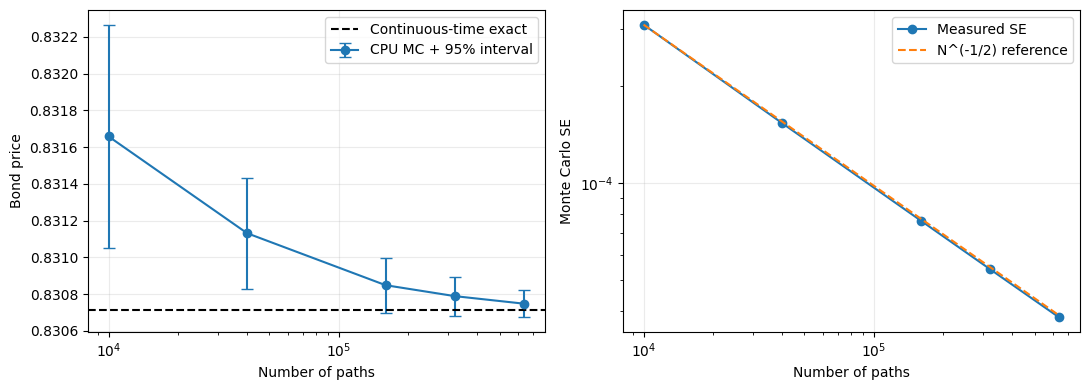

In [30]:
import pandas as pd

records = []
for path_count in [10_000, 40_000, 160_000, 320_000, 640_000]:
    estimate, se = bond_mc_cpu(params, path_count, n_steps, seed)
    records.append({"n_paths": path_count, "price": estimate, "MC_SE": se,
                    "error": estimate - price_exact, "SE_times_sqrt_N": se * np.sqrt(path_count)})
convergence = pd.DataFrame(records)
display(convergence)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].errorbar(convergence["n_paths"], convergence["price"],
                 yerr=1.96 * convergence["MC_SE"], fmt="o-", capsize=4, label="CPU MC + 95% interval")
axes[0].axhline(price_exact, color="black", linestyle="--", label="Continuous-time exact")
axes[0].set(xscale="log", xlabel="Number of paths", ylabel="Bond price")
axes[0].legend()
axes[1].loglog(convergence["n_paths"], convergence["MC_SE"], "o-", label="Measured SE")
axes[1].loglog(convergence["n_paths"], convergence["MC_SE"].iloc[0] * np.sqrt(10_000 / convergence["n_paths"]), "--", label="N^(-1/2) reference")
axes[1].set(xlabel="Number of paths", ylabel="Monte Carlo SE")
axes[1].legend()
for ax in axes: ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 보충 실습: 메모리 사용량 계산

현재 상태만 저장하는 방법과 모든 시간의 경로를 저장하는 방법의 배열 크기를 비교합니다. 아래 표는 배열 크기로부터 계산한 값이며 실제 GPU 메모리 측정값이 아닙니다. 라이브러리의 작업 공간과 난수 생성기의 내부 메모리는 제외합니다.

In [31]:
bytes_per_float = np.dtype(float).itemsize
memory = pd.DataFrame({
    "storage": ["One state array", "Four length-N arrays", "Full path matrix"],
    "MiB": [n_paths * bytes_per_float / 2**20,
            4 * n_paths * bytes_per_float / 2**20,
            (n_steps + 1) * n_paths * bytes_per_float / 2**20]})
display(memory)

,storage,MiB
0,One state array,7.629395
1,Four length-N arrays,30.517578
2,Full path matrix,76301.574707


## 직접 해보기

1. `n_paths`를 네 배로 늘렸을 때 표준오차와 실행시간이 어떻게 달라지는지 기록합니다.
2. 경로 수를 고정하고 `n_steps`를 250, 500, 1000으로 바꾸어 시간 이산화의 영향을 확인합니다.
3. NVIDIA GPU가 있는 환경에서는 위 셀 전체를 다시 실행하여 GPU 가격·표준오차와 실제 속도 향상률을 기록합니다.
4. 비교할 때 CPU와 GPU의 파라미터, 경로 수, 시간 단계 수가 같은지 확인합니다. GPU 시간 측정에는 준비 실행과 동기화가 필요합니다.